# Demo 1 — Zero-shot is the starting line

**Question:** When does a pretrained forecast add value beyond local baselines?

We compare four things at short/medium/long horizons, on two series with very different
signal characteristics:

1. **Seasonal-naive / naive** — the baseline every comparison in this repo must clear.
2. **ARIMA** — a classical, locally-fit model. Its order is chosen once (by AICc grid
   search) and then refit on a rolling window at every forecast origin.
3. **Chronos-2 zero-shot** — a frozen, pretrained time-series foundation model
   ([amazon/chronos-2](https://huggingface.co/amazon/chronos-2)). It only ever sees each
   series as inference-time context; nothing is fit to these series.
4. **A validation-weighted ARIMA / Chronos-2 hybrid** — a convex combination whose weight
   is chosen *only* on a validation slice, then applied unchanged to the held-out test
   period.

The point isn't to crown a winner. It's to keep two different claims from getting
conflated: *"this pretrained model has broad forecasting capability"* and *"this
pretrained model demonstrably helps on my series, at my horizon, right now."* Those are
only the same claim if you check — which is what the validation-only hybrid weight and
the held-out test comparison below are for.

Related reading: [Chasing Chronos](https://medium.com/@eclow/chasing-chronos-663cc8883558),
[Transformers vs. ARIMA](https://medium.com/@eclow/transformers-vs-arima-do-more-complex-models-produce-better-forecasts-28ca372052d4),
and Garcia & Remy (2026) on benchmarking transformer models in low signal-to-noise
settings — the reason SPY is included here alongside CISO electricity demand.

In [1]:
import sys
import warnings

sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import pandas as pd

from src.data import load_electricity, load_spy
from src.evaluation import combine_results, rolling_origin_evaluate, summarize
from src.models import (
    arima_forecast,
    chronos_zero_shot_forecast,
    fit_hybrid_weight,
    naive_forecast,
    seasonal_naive_forecast,
    select_order_by_aicc,
)

# statsmodels re-registers its own warning filters on import, so this has to run after
# the imports above to actually suppress its start-parameter noise in the output below.
warnings.filterwarnings("ignore")

RESULTS_DIR = "../results"


## Scale

`SMALL_SCALE = True` cuts down history, forecast origins, and step size so the whole
notebook runs in a few minutes on a laptop CPU. Set it to `False` and rerun for the
full-scale numbers used in the blog post — expect the ARIMA rolling refit and Chronos-2
zero-shot inference loops to take much longer (mainly a function of how many origins you
ask for).

In [2]:
SMALL_SCALE = True

if SMALL_SCALE:
    CISO_LOOKBACK, CISO_VAL_SIZE, CISO_TEST_SIZE, CISO_STEP = 8_000, 600, 600, 80
    SPY_LOOKBACK, SPY_VAL_SIZE, SPY_TEST_SIZE, SPY_STEP = 1_500, 150, 150, 20
else:
    CISO_LOOKBACK, CISO_VAL_SIZE, CISO_TEST_SIZE, CISO_STEP = None, 2_000, 2_000, 12
    SPY_LOOKBACK, SPY_VAL_SIZE, SPY_TEST_SIZE, SPY_STEP = None, 500, 500, 5


In [3]:
def run_baseline_models(
    series, initial_train_size, horizon_values, step,
    baseline_name, baseline_fn, baseline_kwargs,
    arima_order, arima_window, chronos_context,
):
    """Evaluate baseline / ARIMA / Chronos-2 zero-shot over identical origins."""
    baseline = rolling_origin_evaluate(
        series, baseline_fn, baseline_name, horizon_values,
        initial_train_size, step=step, model_kwargs=baseline_kwargs,
    )
    arima = rolling_origin_evaluate(
        series, arima_forecast, "ARIMA", horizon_values,
        initial_train_size, step=step, window="rolling", window_size=arima_window,
        model_kwargs={"order": arima_order},
    )
    chronos = rolling_origin_evaluate(
        series, chronos_zero_shot_forecast, "Chronos-2 (zero-shot)", horizon_values,
        initial_train_size, step=step, model_kwargs={"max_context_length": chronos_context},
    )
    return {baseline_name: baseline, "ARIMA": arima, "Chronos-2 (zero-shot)": chronos}


def fit_hybrid_weights_by_horizon(val_results, model_a="ARIMA", model_b="Chronos-2 (zero-shot)"):
    """Convex-combination weight on `model_a`, chosen per horizon, validation data only."""
    a = val_results[model_a][["origin", "horizon", "actual", "forecast"]].rename(columns={"forecast": "forecast_a"})
    b = val_results[model_b][["origin", "horizon", "forecast"]].rename(columns={"forecast": "forecast_b"})
    merged = a.merge(b, on=["origin", "horizon"])
    return {
        horizon: fit_hybrid_weight(group["actual"], group["forecast_a"], group["forecast_b"])
        for horizon, group in merged.groupby("horizon")
    }


def build_test_comparison(test_results, hybrid_weights, hybrid_name="Hybrid (val-weighted)"):
    hybrid = combine_results(
        test_results["ARIMA"], test_results["Chronos-2 (zero-shot)"],
        weight=hybrid_weights, model_name=hybrid_name,
    )
    return pd.concat(list(test_results.values()) + [hybrid], ignore_index=True)


def summarize_with_labels(all_results, horizon_labels):
    summary = summarize(all_results)
    summary["horizon_label"] = summary["horizon"].map(horizon_labels)
    columns = ["model", "horizon", "horizon_label", "n_forecasts", "mae", "rmse",
               "mase", "directional_accuracy", "mean_elapsed_seconds"]
    return summary[columns]


def plot_mase_by_horizon(summary, title, path):
    fig, ax = plt.subplots(figsize=(7, 4))
    for model, group in summary.groupby("model"):
        ax.plot(group["horizon"], group["mase"], marker="o", label=model)
    ax.set_xlabel("Horizon")
    ax.set_ylabel("MASE (lower is better)")
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()


## CISO electricity demand (hourly, seasonal, high signal)

In [4]:
ciso = load_electricity("CISO")
if CISO_LOOKBACK:
    ciso = ciso.iloc[-CISO_LOOKBACK:]

ciso_train = ciso.iloc[: len(ciso) - CISO_VAL_SIZE - CISO_TEST_SIZE]
ciso_val_phase = ciso.iloc[: len(ciso) - CISO_TEST_SIZE]   # train + val
ciso_test_phase = ciso                                      # train + val + test

print(f"train={len(ciso_train)}  val={CISO_VAL_SIZE}  test={CISO_TEST_SIZE}")
print(f"train range: {ciso_train.index.min()} -> {ciso_train.index.max()}")
print(f"test range:  {ciso_test_phase.index[-CISO_TEST_SIZE]} -> {ciso_test_phase.index[-1]}")

ciso_horizons = {"short": 6, "medium": 24, "long": 168}  # 6h, 1 day, 1 week ahead
ciso_horizon_values = sorted(ciso_horizons.values())
ciso_season_length = 24
ciso_arima_window = 24 * 60  # 60-day rolling window for ARIMA refits

ciso_arima_order = select_order_by_aicc(ciso_train)
print("Selected ARIMA order for CISO (chosen once, held fixed across origins):", ciso_arima_order)


train=6800  val=600  test=600
train range: 2025-09-18 17:00:00+00:00 -> 2026-06-29 00:00:00+00:00
test range:  2026-07-24 01:00:00+00:00 -> 2026-08-18 00:00:00+00:00


Selected ARIMA order for CISO (chosen once, held fixed across origins): (2, 1, 2)


In [5]:
ciso_val_results = run_baseline_models(
    ciso_val_phase, len(ciso_train), ciso_horizon_values, step=CISO_STEP,
    baseline_name="Seasonal naive", baseline_fn=seasonal_naive_forecast,
    baseline_kwargs={"season_length": ciso_season_length},
    arima_order=ciso_arima_order, arima_window=ciso_arima_window, chronos_context=512,
)

ciso_test_results = run_baseline_models(
    ciso_test_phase, len(ciso_train) + CISO_VAL_SIZE, ciso_horizon_values, step=CISO_STEP,
    baseline_name="Seasonal naive", baseline_fn=seasonal_naive_forecast,
    baseline_kwargs={"season_length": ciso_season_length},
    arima_order=ciso_arima_order, arima_window=ciso_arima_window, chronos_context=512,
)

ciso_hybrid_weights = fit_hybrid_weights_by_horizon(ciso_val_results)
print("Validation-selected hybrid weight on ARIMA, by horizon:", ciso_hybrid_weights)


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Validation-selected hybrid weight on ARIMA, by horizon: {6: 0.2, 24: 0.0, 168: 0.75}


In [6]:
ciso_all_test_results = build_test_comparison(ciso_test_results, ciso_hybrid_weights)
ciso_summary = summarize_with_labels(ciso_all_test_results, {v: k for k, v in ciso_horizons.items()})
ciso_summary


,model,horizon,horizon_label,n_forecasts,mae,rmse,mase,directional_accuracy,mean_elapsed_seconds
0,ARIMA,6,short,6,1810.309027,2392.424168,1.718508,0.666667,0.481348
1,ARIMA,24,medium,6,4077.073479,4731.484377,3.922984,0.500000,0.481348
2,ARIMA,168,long,6,4392.969744,4611.924794,4.186774,0.166667,0.481348
3,Chronos-2 (zero-shot),6,short,6,643.831706,873.378278,0.771218,0.833333,0.118483
4,Chronos-2 (zero-shot),24,medium,6,935.395508,1132.154873,1.118530,0.833333,0.118483
5,Chronos-2 (zero-shot),168,long,6,1366.825521,2083.310975,1.620451,0.666667,0.118483
6,Hybrid (val-weighted),6,short,6,622.869271,718.887695,0.601532,0.833333,0.000000
7,Hybrid (val-weighted),24,medium,6,935.395508,1132.154873,0.898310,0.833333,0.000000
8,Hybrid (val-weighted),168,long,6,3598.795016,3851.777421,3.418057,0.166667,0.000000
9,Seasonal naive,6,short,6,1100.166667,1492.413761,1.325510,0.833333,0.000089


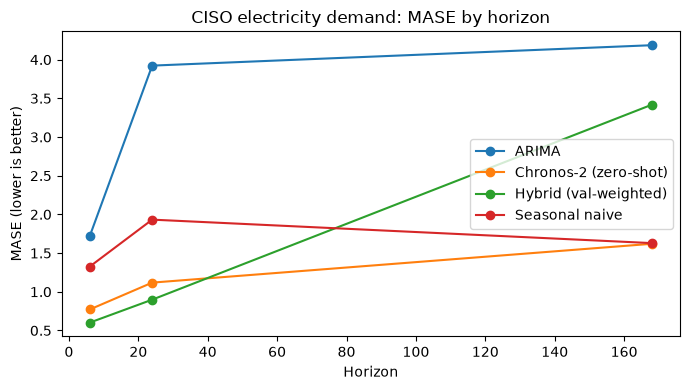

In [7]:
plot_mase_by_horizon(
    ciso_summary, "CISO electricity demand: MASE by horizon",
    f"{RESULTS_DIR}/figures/demo1_ciso_mase_by_horizon.png",
)


In [8]:
ciso_summary.to_csv(f"{RESULTS_DIR}/metrics/demo1_ciso_summary.csv", index=False)
ciso_all_test_results.to_csv(f"{RESULTS_DIR}/metrics/demo1_ciso_test_forecasts.csv", index=False)


## SPY daily close (low signal-to-noise)

In [9]:
spy = load_spy()
if SPY_LOOKBACK:
    spy = spy.iloc[-SPY_LOOKBACK:]

spy_train = spy.iloc[: len(spy) - SPY_VAL_SIZE - SPY_TEST_SIZE]
spy_val_phase = spy.iloc[: len(spy) - SPY_TEST_SIZE]
spy_test_phase = spy

print(f"train={len(spy_train)}  val={SPY_VAL_SIZE}  test={SPY_TEST_SIZE}")
print(f"train range: {spy_train.index.min()} -> {spy_train.index.max()}")
print(f"test range:  {spy_test_phase.index[-SPY_TEST_SIZE]} -> {spy_test_phase.index[-1]}")

spy_horizons = {"short": 1, "medium": 5, "long": 20}  # 1 day, 1 week, ~1 month of trading days
spy_horizon_values = sorted(spy_horizons.values())
spy_arima_window = 500  # rolling window of trading days for ARIMA refits

spy_arima_order = select_order_by_aicc(spy_train)
print("Selected ARIMA order for SPY (chosen once, held fixed across origins):", spy_arima_order)


train=1200  val=150  test=150
train range: 2020-08-26 00:00:00 -> 2025-06-05 00:00:00
test range:  2026-01-12 00:00:00 -> 2026-08-17 00:00:00


Selected ARIMA order for SPY (chosen once, held fixed across origins): (0, 1, 0)


In [10]:
spy_val_results = run_baseline_models(
    spy_val_phase, len(spy_train), spy_horizon_values, step=SPY_STEP,
    baseline_name="Naive", baseline_fn=naive_forecast, baseline_kwargs={},
    arima_order=spy_arima_order, arima_window=spy_arima_window, chronos_context=512,
)

spy_test_results = run_baseline_models(
    spy_test_phase, len(spy_train) + SPY_VAL_SIZE, spy_horizon_values, step=SPY_STEP,
    baseline_name="Naive", baseline_fn=naive_forecast, baseline_kwargs={},
    arima_order=spy_arima_order, arima_window=spy_arima_window, chronos_context=512,
)

spy_hybrid_weights = fit_hybrid_weights_by_horizon(spy_val_results)
print("Validation-selected hybrid weight on ARIMA, by horizon:", spy_hybrid_weights)


Validation-selected hybrid weight on ARIMA, by horizon: {1: 1.0, 5: 0.0, 20: 0.0}


In [11]:
spy_all_test_results = build_test_comparison(spy_test_results, spy_hybrid_weights)
spy_summary = summarize_with_labels(spy_all_test_results, {v: k for k, v in spy_horizons.items()})
spy_summary


,model,horizon,horizon_label,n_forecasts,mae,rmse,mase,directional_accuracy,mean_elapsed_seconds
0,ARIMA,1,short,7,4.706273,7.727217,1.154976,0.000000,0.013528
1,ARIMA,5,medium,7,10.501700,13.013664,2.627221,0.000000,0.013528
2,ARIMA,20,long,7,15.514221,24.491225,3.869050,0.000000,0.013528
3,Chronos-2 (zero-shot),1,short,7,5.170750,8.708164,1.490989,0.428571,0.113292
4,Chronos-2 (zero-shot),5,medium,7,11.961818,15.126072,3.462993,0.000000,0.113292
5,Chronos-2 (zero-shot),20,long,7,17.619899,25.581325,5.108147,0.428571,0.113292
6,Hybrid (val-weighted),1,short,7,4.706273,7.727217,1.154976,0.000000,0.000000
7,Hybrid (val-weighted),5,medium,7,11.961818,15.126072,2.988998,0.000000,0.000000
8,Hybrid (val-weighted),20,long,7,17.619899,25.581325,4.431757,0.428571,0.000000
9,Naive,1,short,7,4.706273,7.727217,1.356806,0.000000,0.000016


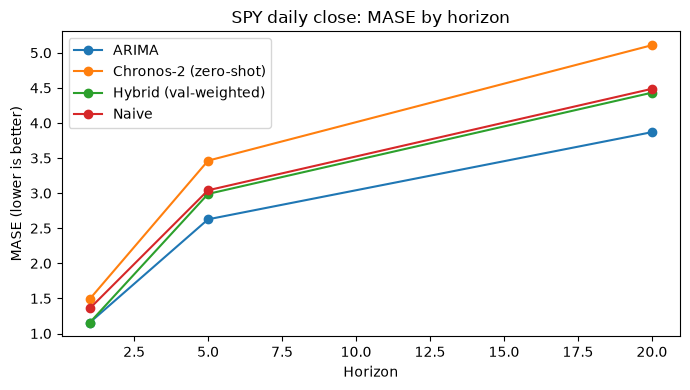

In [12]:
plot_mase_by_horizon(
    spy_summary, "SPY daily close: MASE by horizon",
    f"{RESULTS_DIR}/figures/demo1_spy_mase_by_horizon.png",
)


In [13]:
spy_summary.to_csv(f"{RESULTS_DIR}/metrics/demo1_spy_summary.csv", index=False)
spy_all_test_results.to_csv(f"{RESULTS_DIR}/metrics/demo1_spy_test_forecasts.csv", index=False)


## Reading the results

- MASE is scaled so that **1.0 is the naive / seasonal-naive baseline** at that horizon.
  Anything below 1.0 beat the baseline; anything above it didn't.
- If Chronos-2 zero-shot doesn't beat the local ARIMA baseline at a given horizon, that
  *is* a finding: broad zero-shot competence elsewhere doesn't automatically transfer to
  this series, at this horizon, on its own.
- Look at where the validation-selected hybrid weight landed for each horizon (printed
  above each summary table). A weight near 0 or 1 means validation data found no benefit
  to combining ARIMA and Chronos-2; a weight strictly between 0 and 1 means the
  combination was locally useful — and only because we checked on validation data first,
  not because either model is generically better.
- `mean_elapsed_seconds` in the summary tables puts a number on the cost side: ARIMA is
  refit from scratch at every forecast origin, while Chronos-2 zero-shot only ever runs
  inference. Compare that to whatever accuracy gap you see above.
- Set `SMALL_SCALE = False` near the top of the notebook and rerun for the full-scale
  numbers used in the blog post.